In [2]:

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [4]:
# 2. Load dataset
data = pd.read_csv("student-por.csv", sep=";")

print("First 5 rows:")
print(data.head())

print("\nDataset Shape:")
print(data.shape)

First 5 rows:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]

Dataset Shape:
(649, 33)


In [8]:
# 3. Create Pass / Fail target
data["Result"] = (data["G3"] >= 10).astype(int)


In [16]:
# 4. Separate input and output
X = data.drop(["G3", "Result"], axis=1)
y = data["Result"]


In [19]:
# 5. Convert text columns into numbers
X = pd.get_dummies(X, drop_first=True, dtype=int)


In [20]:
# 6. Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [22]:
# 7. Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [23]:
# 8. Create Logistic Regression model
model = LogisticRegression(max_iter=1000)

In [24]:
# 9. Train the model
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [25]:
# 10. Make predictions
y_pred = model.predict(X_test)

In [28]:
# 11. Check model accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", accuracy * 100, "%")


Model Accuracy: 90.76923076923077 %


In [29]:
# 12. Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fail", "Pass"],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

        Fail       0.72      0.65      0.68        20
        Pass       0.94      0.95      0.95       110

    accuracy                           0.91       130
   macro avg       0.83      0.80      0.82       130
weighted avg       0.90      0.91      0.91       130



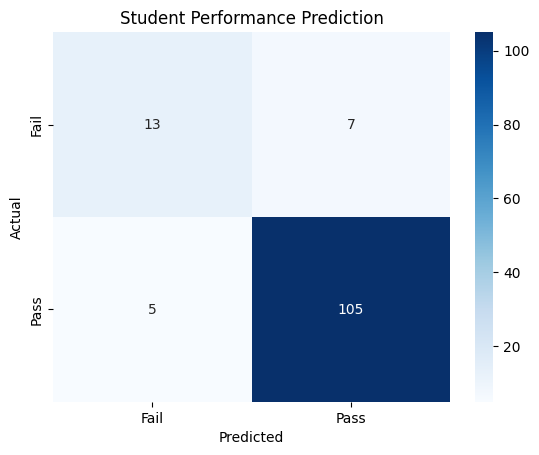

In [30]:
# 13. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Student Performance Prediction")
plt.show()

In [31]:
sample = X_test[0].reshape(1, -1)

prediction = model.predict(sample)

if prediction[0] == 1:
    print("\nStudent Result: PASS")


Student Result: PASS
